<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Dataset shape: (400, 4096) (400 faces, 64x64 pixels)

=== Verification: Scratch PCA vs Scikit-learn PCA (Top 100 Components) ===
Max Explained Variance Ratio Diff : 8.92e-08 -> MATCH
Max Reconstruction Pixel Diff     : 3.58e-06 -> MATCH

Components needed to retain 95% variance: 123 (out of 4096 pixels)
Dimensionality reduction: 97.00%



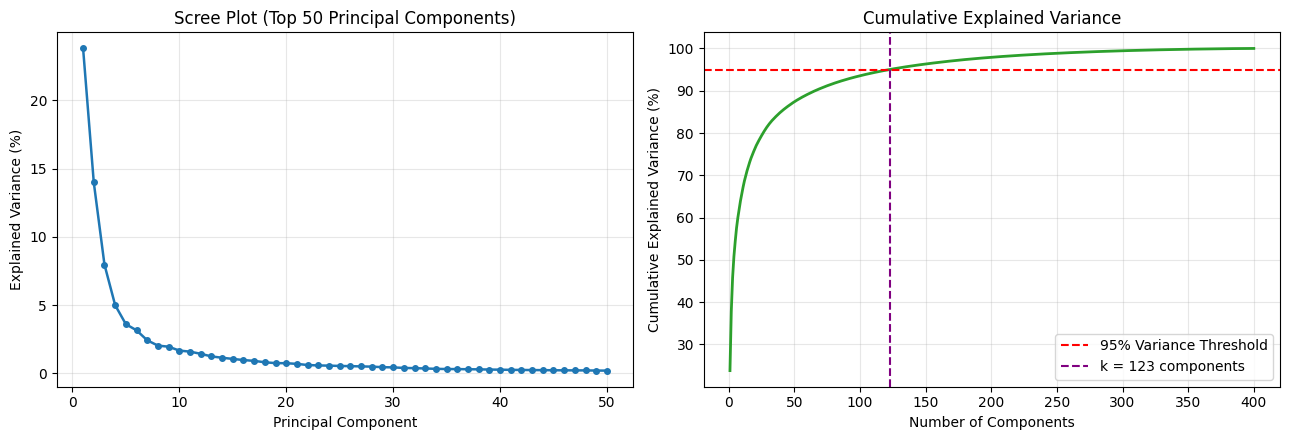

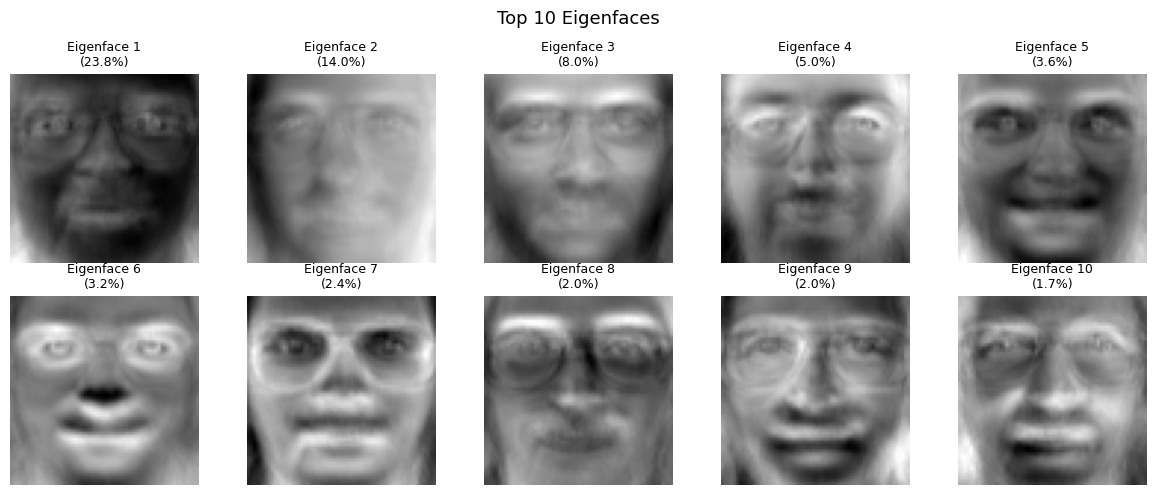

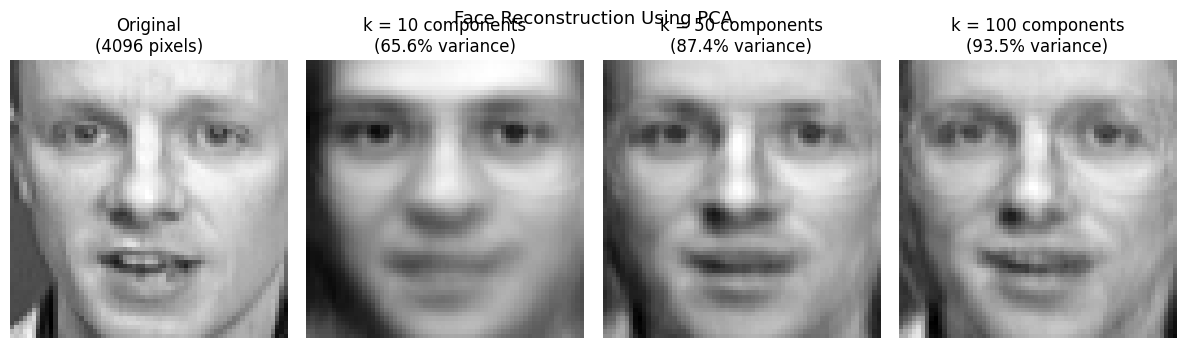

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA

# ==========================================
# Load Olivetti Faces Dataset (400 images, 64x64)
# ==========================================
faces = fetch_olivetti_faces(shuffle=True, random_state=42)
X = faces.data          # shape: (400, 4096)
img_shape = (64, 64)
n_samples, n_features = X.shape

print(f"Dataset shape: {X.shape} ({n_samples} faces, {img_shape[0]}x{img_shape[1]} pixels)\n")

# ==========================================
# Task 1: PCA from Scratch (Covariance Matrix + Eigen-decomposition)
# ==========================================
X_mean = np.mean(X, axis=0)
X_centered = X - X_mean

# Covariance matrix (4096 x 4096) and symmetric eigen-decomposition
cov_matrix = np.cov(X_centered, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov_matrix)

# Sort eigenvalues & eigenvectors in descending order
idx = np.argsort(eigvals)[::-1]
eigvals = np.maximum(eigvals[idx], 0.0)   # Clip tiny negative numerical noise
eigvecs = eigvecs[:, idx]                 # Columns are principal components

# Keep top n_samples components (max rank is n_samples - 1 = 399)
max_k = n_samples
eigvals_k = eigvals[:max_k]
eigvecs_k = eigvecs[:, :max_k]

explained_var_ratio_scratch = eigvals_k / np.sum(eigvals)
cum_var_scratch = np.cumsum(explained_var_ratio_scratch)

def reconstruct_scratch(X_cent, mean, vecs, k):
    W = vecs[:, :k]
    Z = X_cent @ W
    return Z @ W.T + mean

# ==========================================
# Task 2: Verify Against Scikit-learn's PCA
# ==========================================
sk_pca = PCA(n_components=100, svd_solver="full")
Z_sk = sk_pca.fit_transform(X)
X_recon_sk = sk_pca.inverse_transform(Z_sk)
X_recon_scratch_100 = reconstruct_scratch(X_centered, X_mean, eigvecs_k, 100)

var_diff = np.max(np.abs(explained_var_ratio_scratch[:100] - sk_pca.explained_variance_ratio_))
recon_diff = np.max(np.abs(X_recon_scratch_100 - X_recon_sk))

print("=== Verification: Scratch PCA vs Scikit-learn PCA (Top 100 Components) ===")
print(f"Max Explained Variance Ratio Diff : {var_diff:.2e} -> {'MATCH' if var_diff < 1e-6 else 'MISMATCH'}")
print(f"Max Reconstruction Pixel Diff     : {recon_diff:.2e} -> {'MATCH' if recon_diff < 1e-4 else 'MISMATCH'}\n")

# ==========================================
# Task 4: Find Number of Components Retaining 95% Variance
# ==========================================
n_95 = int(np.argmax(cum_var_scratch >= 0.95) + 1)
print(f"Components needed to retain 95% variance: {n_95} (out of {n_features} pixels)")
print(f"Dimensionality reduction: {(1 - n_95 / n_features) * 100:.2f}%\n")

# ==========================================
# Task 3: Scree Plot & Cumulative Explained Variance
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Scree plot (Top 50 components for clarity)
axes[0].plot(range(1, 51), explained_var_ratio_scratch[:50] * 100, marker="o", markersize=4, linewidth=1.8)
axes[0].set_title("Scree Plot (Top 50 Principal Components)")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance (%)")
axes[0].grid(True, alpha=0.3)

# Cumulative explained variance
axes[1].plot(range(1, max_k + 1), cum_var_scratch * 100, linewidth=2, color="tab:green")
axes[1].axhline(95, color="red", linestyle="--", label="95% Variance Threshold")
axes[1].axvline(n_95, color="purple", linestyle="--", label=f"k = {n_95} components")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Explained Variance (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# Task 5a: Visualise Top 10 Eigenfaces
# ==========================================
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(eigvecs_k[:, i].reshape(img_shape), cmap="gray")
    ax.set_title(f"Eigenface {i+1}\n({explained_var_ratio_scratch[i]*100:.1f}%)", fontsize=9)
    ax.axis("off")
plt.suptitle("Top 10 Eigenfaces", fontsize=13)
plt.tight_layout()
plt.show()

# ==========================================
# Task 5b: Reconstructed Faces with 10, 50, and 100 Components
# ==========================================
sample_idx = 0
k_values = [10, 50, 100]

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
axes[0].imshow(X[sample_idx].reshape(img_shape), cmap="gray")
axes[0].set_title("Original\n(4096 pixels)")
axes[0].axis("off")

for ax, k in zip(axes[1:], k_values):
    recon = reconstruct_scratch(X_centered[sample_idx:sample_idx+1], X_mean, eigvecs_k, k)
    var_pct = cum_var_scratch[k - 1] * 100
    ax.imshow(recon.reshape(img_shape), cmap="gray")
    ax.set_title(f"k = {k} components\n({var_pct:.1f}% variance)")
    ax.axis("off")

plt.suptitle("Face Reconstruction Using PCA", fontsize=13)
plt.tight_layout()
plt.show()